# Lecture 13: Why taking logs preserves argmax and argmin

**CSCI 6032 · Loss and Risk**

Taking a logarithm changes objective values and the shape of a graph, but an increasing logarithm preserves their ordering. This notebook states the precise conditions, proves the result, and demonstrates it for ordinary functions, likelihoods, and likelihood ratios.

After working through the examples, you should be able to:

- Check whether a log transformation is valid on the entire feasible set.
- Distinguish an extremum's **location** (`argmax` or `argmin`) from its **value** (`max` or `min`).
- Explain why a log-likelihood ratio gives the same rankings and threshold decisions as a likelihood ratio.
- Identify the extra issues caused by zeros, decreasing transforms, and floating-point arithmetic.

Run the cells in order. Dependencies: Python 3, NumPy, and Matplotlib. All data are generated here; no downloads are needed.

## 1. Exact conditions and proof

Let $S$ be a nonempty feasible set, and let $f:S\to(0,\infty)$ be finite and strictly positive at every feasible point. Use the **same feasible set** before and after the transformation, and choose a logarithm base $b>1$ (such as $e$, $2$, or $10$). Then

$$\boxed{\operatorname*{argmax}_{x\in S}f(x)
=\operatorname*{argmax}_{x\in S}\log_b f(x)}$$

and

$$\boxed{\operatorname*{argmin}_{x\in S}f(x)
=\operatorname*{argmin}_{x\in S}\log_b f(x).}$$

These are **equalities of sets**, so they preserve every tied optimum. By definition,

$$\operatorname*{argmax}_{x\in S} f(x)
=\{x\in S:f(x)\ge f(y)\text{ for every }y\in S\}.$$

**Proof.** The logarithm is strictly increasing on $(0,\infty)$. Thus, for any $x,y\in S$,

$$f(x)\ge f(y)\iff\log_b f(x)\ge\log_b f(y),$$

with the same equivalence for $\le$ and $=$. Substituting these equivalences into the definitions of argmax and argmin proves both claims.

No continuity, differentiability, concavity, or normalization as a probability is required. Positive values less than one are fine: their logarithms are negative but still ordered correctly. Values greater than one are also fine.

**Existence is a separate question.** If an extremum is not attained, its arg-set is empty on both sides. For example, $f(x)=x$ on $(0,1)$ has neither a maximum nor a minimum; taking logs does not create one. A finite feasible set, or a continuous positive function on a nonempty compact set, guarantees that both extrema are attained.

**Other transformations.** Any strictly increasing transformation defined on the range of $f$ has the same property. If $0<b<1$, $\log_b$ is strictly decreasing and swaps argmax with argmin. Likewise,

$$\operatorname*{argmax} f=\operatorname*{argmin}(-\ln f),\qquad
\operatorname*{argmin} f=\operatorname*{argmax}(-\ln f).$$

The objective values generally change: when a maximum is attained, $\max\log_b f=\log_b(\max f)$, not $\max f$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

def extreme_indices(values, kind):
    """All exact ties in a finite array; these are grid extrema, not a proof."""
    values = np.asarray(values)
    target = values.max() if kind == "max" else values.min()
    return np.flatnonzero(values == target)

def verify_log_extrema(values):
    values = np.asarray(values, dtype=float)
    assert np.all(np.isfinite(values)) and np.all(values > 0)
    logs = np.log(values)
    for kind in ("max", "min"):
        assert np.array_equal(extreme_indices(values, kind),
                              extreme_indices(logs, kind))
    return logs

## 2. A finite example: ties and negative log values

The candidate scores below include values both below and above one, with ties at the maximum and minimum. Logarithms preserve all four tied locations. NumPy's `argmax` and `argmin` return only the first index in a tie, so we explicitly collect the full sets.

candidate     score      ln(score)
    A         0.20        -1.6094
    B         4.00         1.3863
    C         1.00         0.0000
    D         4.00         1.3863
    E         0.20        -1.6094
    F         2.00         0.6931
argmax before and after log: ['B', 'D']
argmin before and after log: ['A', 'E']


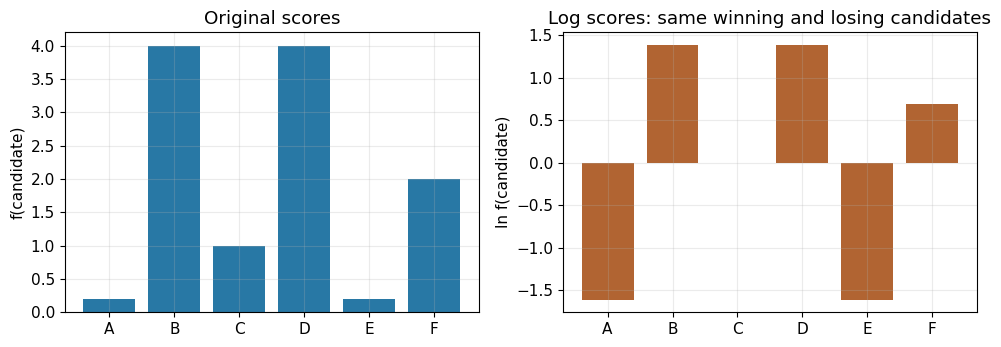

In [2]:
labels = np.array(["A", "B", "C", "D", "E", "F"])
scores = np.array([0.2, 4.0, 1.0, 4.0, 0.2, 2.0])
logs = verify_log_extrema(scores)

print("candidate     score      ln(score)")
for label, score, log_score in zip(labels, scores, logs):
    print(f"{label:>5}       {score:6.2f}       {log_score:8.4f}")
for kind in ("max", "min"):
    print(f"arg{kind} before and after log: "
          f"{labels[extreme_indices(scores, kind)].tolist()}")

fig, axes = plt.subplots(1, 2)
axes[0].bar(labels, scores, color="#2878a5")
axes[1].bar(labels, logs, color="#b16432")
axes[0].set(title="Original scores", ylabel="f(candidate)")
axes[1].set(title="Log scores: same winning and losing candidates", ylabel="ln f(candidate)")
fig.tight_layout()
plt.show()

## 3. Continuous functions: one maximization and one minimization

For $S=[-4,4]$, consider

$$f(x)=\exp\!\left(-\frac{(x-1)^2}{2}\right),\qquad
g(x)=(x+1.5)^2+0.25.$$

Both are positive everywhere. Since $(x-1)^2\ge0$, $f$ and $\ln f=-(x-1)^2/2$ have their unique maximum at $x=1$. Since $(x+1.5)^2\ge0$, $g$ and $\ln g$ have their unique minimum at $x=-1.5$. These algebraic arguments establish the exact continuous optima; the plots and grid checks illustrate them.

For a differentiable positive $f$, $(\ln f)'=f'/f$ also shows why stationary points coincide. The order proof is stronger: it covers boundaries, ties, discrete domains, and functions without derivatives.

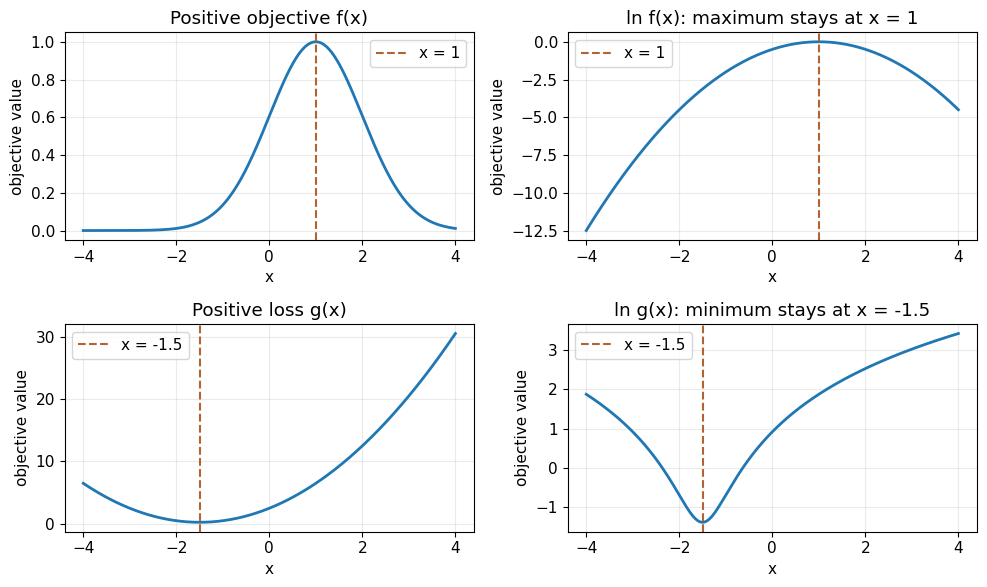

Grid argmax f = argmax ln f = 1.0
Grid argmin g = argmin ln g = -1.5


In [3]:
x = np.linspace(-4, 4, 1601)
peak = np.exp(-0.5 * (x - 1)**2)
loss = (x + 1.5)**2 + 0.25
log_peak = verify_log_extrema(peak)
log_loss = verify_log_extrema(loss)
assert np.isclose(x[np.argmax(peak)], 1)
assert np.isclose(x[np.argmin(loss)], -1.5)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, values, title, optimum in [
    (axes[0, 0], peak, "Positive objective f(x)", 1),
    (axes[0, 1], log_peak, "ln f(x): maximum stays at x = 1", 1),
    (axes[1, 0], loss, "Positive loss g(x)", -1.5),
    (axes[1, 1], log_loss, "ln g(x): minimum stays at x = -1.5", -1.5),
]:
    ax.plot(x, values, lw=2)
    ax.axvline(optimum, color="#b16432", ls="--", label=f"x = {optimum:g}")
    ax.set(title=title, xlabel="x", ylabel="objective value")
    ax.legend()
fig.tight_layout()
plt.show()
print("Grid argmax f = argmax ln f =", x[np.argmax(peak)])
print("Grid argmin g = argmin ln g =", x[np.argmin(loss)])

## 4. Bernoulli likelihood: products become sums

Suppose ten independent Bernoulli trials contain $k=7$ successes. For the observed **ordered sequence**, its likelihood as a function of the success probability $\theta$ is

$$L(\theta)=\theta^7(1-\theta)^3,\qquad 0<\theta<1.$$

Every factor is finite and strictly positive on this domain. Consequently,

$$\ell(\theta)=\ln L(\theta)=7\ln\theta+3\ln(1-\theta)$$

has the same argmax. Solving $\ell'(\theta)=7/\theta-3/(1-\theta)=0$ gives $\hat\theta=0.7$. Its second derivative is negative throughout $(0,1)$, proving this is the unique global maximizer. Equivalently, the negative log-likelihood has its unique **minimum** there.

For the probability of the **count** $k=7$ instead, multiply $L$ by $\binom{10}{7}$. This positive constant does not depend on $\theta$, so it changes neither optimizer. In log space it becomes an additive constant.

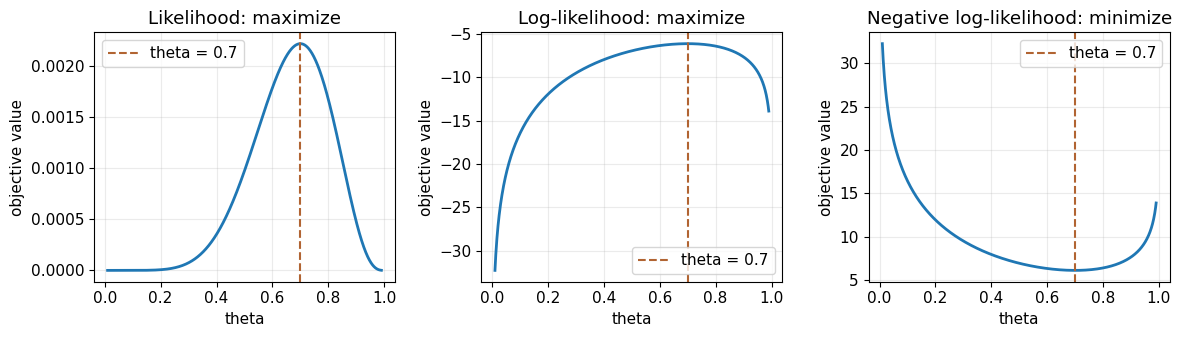

All three optimization problems select theta = 0.7000000000000001


In [4]:
theta = np.linspace(0.01, 0.99, 981)
k, n = 7, 10
likelihood = theta**k * (1 - theta)**(n - k)
log_likelihood = k * np.log(theta) + (n - k) * np.log1p(-theta)
verify_log_extrema(likelihood)
np.testing.assert_allclose(log_likelihood, np.log(likelihood))
assert np.isclose(theta[np.argmax(likelihood)], k / n)
assert np.argmax(likelihood) == np.argmax(log_likelihood)
assert np.argmax(likelihood) == np.argmin(-log_likelihood)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, values, title in zip(axes, [likelihood, log_likelihood, -log_likelihood],
                            ["Likelihood: maximize", "Log-likelihood: maximize",
                             "Negative log-likelihood: minimize"]):
    ax.plot(theta, values, lw=2)
    ax.axvline(k / n, color="#b16432", ls="--", label="theta = 0.7")
    ax.set(title=title, xlabel="theta", ylabel="objective value")
    ax.legend()
fig.tight_layout()
plt.show()
print("All three optimization problems select theta =", theta[np.argmax(likelihood)])

## 5. Likelihood ratios: exactly why the conditions hold

For two classes $\omega_1,\omega_2$, write

$$\Lambda(x)=\frac{p(x\mid\omega_1)}{p(x\mid\omega_2)}.$$

For **each feasible $x$**, if both likelihoods are finite and strictly positive, the denominator is nonzero and

$$0<\Lambda(x)<\infty,\qquad
\ln\Lambda(x)=\ln p(x\mid\omega_1)-\ln p(x\mid\omega_2).$$

Therefore $\Lambda$ meets precisely the hypotheses of Section 1: both argmax and argmin over the same feasible set are preserved by taking its log. The same argument applies if the optimization variable is a model parameter instead of $x$, provided these conditions hold throughout that parameter domain.

Likelihoods are nonnegative in general; they are **not automatically strictly positive**. The ordinary real-log argument applies on their common positive support, not blindly on all observations. Densities and their ratios can exceed one; neither has to be a normalized probability as a function of the optimization variable.

### Gaussian example with an attained maximum

Let $p(x\mid\omega_1)$ be $\mathcal N(1,0.8^2)$ and $p(x\mid\omega_2)$ be $\mathcal N(-1,1.7^2)$. A Gaussian with positive variance has a finite, strictly positive density for every finite real $x$. Thus the ratio is positive and finite in exact arithmetic. Its log is

$$\ln\Lambda(x)=\ln\frac{\sigma_2}{\sigma_1}
-\frac{(x-\mu_1)^2}{2\sigma_1^2}
+\frac{(x-\mu_2)^2}{2\sigma_2^2}.$$

Here $\sigma_1<\sigma_2$, so this quadratic is strictly concave. Its unique maximizer on $\mathbb R$ is

$$x^*=\frac{\mu_1/\sigma_1^2-\mu_2/\sigma_2^2}
{1/\sigma_1^2-1/\sigma_2^2}.$$

We plot on $S=[-4,4]$, which contains $x^*$. The minimum on this interval is at $-4$ for these parameters. On all of $\mathbb R$ there is **no attained minimum**: $\Lambda(x)\to0$ and $\ln\Lambda(x)\to-\infty$ in the tails, so both argmin sets are empty. Positivity does not by itself ensure an extremum exists.

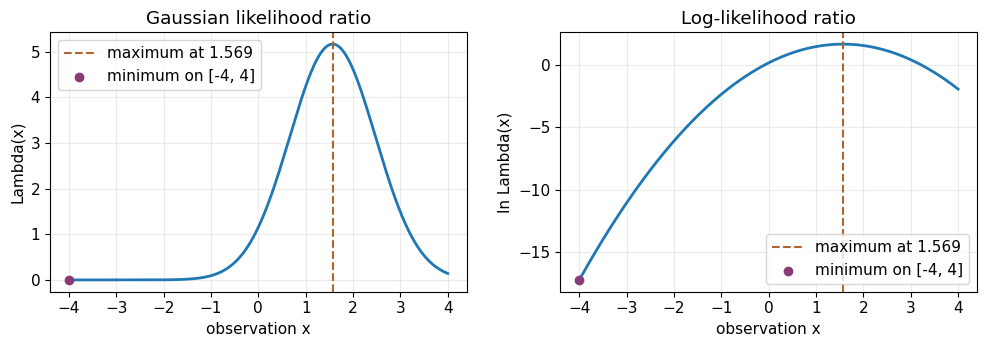

argmax on [-4, 4]: ratio and log ratio both select x = 1.568889
argmin on [-4, 4]: ratio and log ratio both select x = -4


In [5]:
def normal_logpdf(x, mu, sigma):
    return -np.log(sigma) - 0.5 * np.log(2 * np.pi) - 0.5 * ((x - mu) / sigma)**2

mu1, sigma1 = 1.0, 0.8
mu2, sigma2 = -1.0, 1.7
x_star = (mu1 / sigma1**2 - mu2 / sigma2**2) / (1 / sigma1**2 - 1 / sigma2**2)
# Include the exact analytic maximum in the plotting grid.
x_lr = np.sort(np.append(np.linspace(-4, 4, 1601), x_star))
logp1 = normal_logpdf(x_lr, mu1, sigma1)
logp2 = normal_logpdf(x_lr, mu2, sigma2)
log_ratio = logp1 - logp2
ratio = np.exp(logp1) / np.exp(logp2)
np.testing.assert_allclose(np.log(ratio), log_ratio, atol=1e-14)
verify_log_extrema(ratio)
assert np.argmax(ratio) == np.argmax(log_ratio)
assert np.argmin(ratio) == np.argmin(log_ratio)
assert np.isclose(x_lr[np.argmax(ratio)], x_star)
assert x_lr[np.argmin(ratio)] == -4

fig, axes = plt.subplots(1, 2)
for ax, values, title, ylabel in [
    (axes[0], ratio, "Gaussian likelihood ratio", "Lambda(x)"),
    (axes[1], log_ratio, "Log-likelihood ratio", "ln Lambda(x)"),
]:
    ax.plot(x_lr, values, lw=2)
    ax.axvline(x_star, color="#b16432", ls="--", label=f"maximum at {x_star:.3f}")
    ax.scatter([-4], [values[0]], color="#883b74", zorder=3, label="minimum on [-4, 4]")
    ax.set(title=title, xlabel="observation x", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
plt.show()
print(f"argmax on [-4, 4]: ratio and log ratio both select x = {x_star:.6f}")
print("argmin on [-4, 4]: ratio and log ratio both select x = -4")

### Connection to Lecture 13: loss, priors, and a decision threshold

In the lecture's notation, $\lambda_{ij}$ is the loss for choosing action $a_i$ when the true class is $\omega_j$. If

$$\lambda_{21}>\lambda_{11},\quad\lambda_{12}>\lambda_{22},
\quad P(\omega_1)>0,\quad P(\omega_2)>0,$$

then minimizing conditional risk gives the following rule (assign ties to $a_2$):

$$R(a_1\mid x)<R(a_2\mid x)
\iff\Lambda(x)>\eta,\qquad
\eta=\frac{\lambda_{12}-\lambda_{22}}{\lambda_{21}-\lambda_{11}}
\frac{P(\omega_2)}{P(\omega_1)}>0.$$

This is the positive-differences form of the threshold in the lecture. Because **both sides are positive**,

$$\Lambda(x)>\eta\iff\ln\Lambda(x)>\ln\eta.$$

The decision is unchanged, and equality stays equality. Positive priors can instead be absorbed into a posterior-odds score:

$$\ln\frac{p(x\mid\omega_1)P(\omega_1)}{p(x\mid\omega_2)P(\omega_2)}
=\ln\Lambda(x)+\ln P(\omega_1)-\ln P(\omega_2).$$

**Keep the optimization variable clear:** the previous example ranks possible observations $x$ by a ratio. Classification holds the observed $x$ fixed and chooses an **action**. A ratio test is a threshold comparison, not an argmax over possible observations. For zero-one loss, choosing the largest positive class score $p(x\mid\omega_i)P(\omega_i)$ is an argmax **over classes**, and logging every score preserves that choice as well.

Below, $P(\omega_1)=0.4$, $P(\omega_2)=0.6$, and the loss matrix is $\left[\begin{smallmatrix}0&2\\1&0\end{smallmatrix}\right]$, so $\eta=3$. We check the risk rule, ratio test, and log-ratio test against each other.

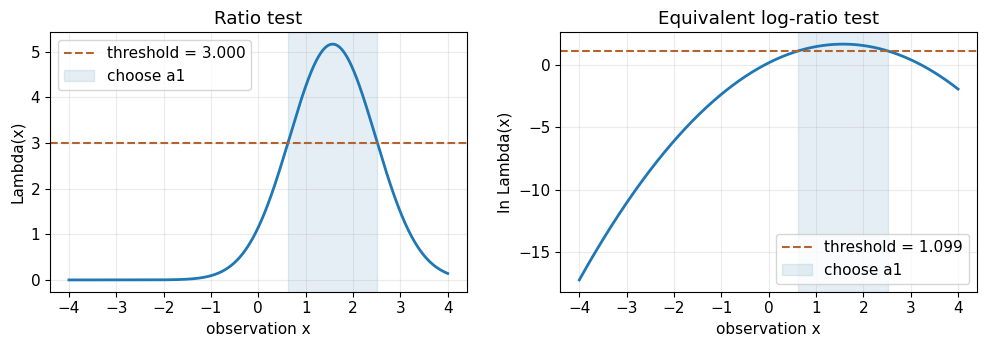

eta = 3, ln(eta) = 1.098612
Risk rule, ratio test, and log-ratio test agree at all 1602 grid points.


In [6]:
prior1, prior2 = 0.4, 0.6
loss_matrix = np.array([[0.0, 2.0], [1.0, 0.0]])
eta = ((loss_matrix[0, 1] - loss_matrix[1, 1]) /
       (loss_matrix[1, 0] - loss_matrix[0, 0])) * prior2 / prior1

joint = np.vstack([np.exp(logp1) * prior1, np.exp(logp2) * prior2])
posterior = joint / joint.sum(axis=0)
conditional_risks = loss_matrix @ posterior
# Boolean True means choose action a1; False includes ties and means a2.
choose1_risk = conditional_risks[0] < conditional_risks[1]
choose1_ratio = ratio > eta
choose1_log = log_ratio > np.log(eta)
assert np.array_equal(choose1_risk, choose1_ratio)
assert np.array_equal(choose1_ratio, choose1_log)

# Here risks are positive, so logging the entire risk also preserves argmin.
assert np.all(conditional_risks > 0)
assert np.array_equal(np.argmin(conditional_risks, axis=0),
                      np.argmin(np.log(conditional_risks), axis=0))

# Zero-one loss: an argmax over classes gives the same answer in log space.
log_joint = np.vstack([logp1 + np.log(prior1), logp2 + np.log(prior2)])
assert np.array_equal(np.argmax(joint, axis=0), np.argmax(log_joint, axis=0))

fig, axes = plt.subplots(1, 2)
for ax, values, threshold, title, ylabel in [
    (axes[0], ratio, eta, "Ratio test", "Lambda(x)"),
    (axes[1], log_ratio, np.log(eta), "Equivalent log-ratio test", "ln Lambda(x)"),
]:
    ax.plot(x_lr, values, lw=2)
    ax.axhline(threshold, color="#b16432", ls="--", label=f"threshold = {threshold:.3f}")
    ax.fill_between(x_lr, 0, 1, where=choose1_log, transform=ax.get_xaxis_transform(),
                    alpha=0.12, color="#2878a5", label="choose a1")
    ax.set(title=title, xlabel="observation x", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
plt.show()
print(f"eta = {eta:g}, ln(eta) = {np.log(eta):.6f}")
print(f"Risk rule, ratio test, and log-ratio test agree at all {x_lr.size} grid points.")

## 6. Boundaries and transformations that need care

| Situation | What follows |
|---|---|
| $f(x)>0$ and finite everywhere on the same $S$; log base $>1$ | Both argmax and argmin are preserved. |
| $f(x)=0$ somewhere | Ordinary real $\log f$ is undefined there. Restricting the domain may remove an optimum. |
| Extended-real convention $\log0=-\infty$ | For finite nonnegative $f$, the extension is strictly increasing on $[0,\infty)$ and preserves both arg-sets, including zero-valued minima. Implement deliberately. |
| $f(x)<0$ somewhere | The real logarithm is undefined; the theorem does not apply. Taking $\log|f|$ changes the objective. |
| Log base between $0$ and $1$, or negative log | Ordering reverses, so argmax and argmin swap. |
| A transform is only nondecreasing, such as rounding | It can introduce ties and enlarge an arg-set. Strict monotonicity guarantees all ties are preserved exactly. |

For likelihood ratios: a zero numerator with a positive denominator gives $\Lambda=0$ and extended $\ln\Lambda=-\infty$; a positive numerator with a zero denominator can be treated as infinite evidence with extended $\ln\Lambda=+\infty$. A $0/0$ ratio is undefined and cannot be repaired by logging. Handle support cases explicitly. The finite, ordinary-real theorem applies where both likelihoods are finite and positive.

If a decision threshold is zero or negative, its ordinary real logarithm is unavailable; analyze the original inequality directly. The positive priors and strict loss inequalities above guarantee a positive finite threshold when the losses are finite.

In [7]:
# Zero is a true minimum. Dropping it changes the feasible set and the argmin.
values = np.array([0.0, 0.2, 1.0])
extended_logs = np.full_like(values, -np.inf)
positive = values > 0
extended_logs[positive] = np.log(values[positive])
assert np.argmin(values) == np.argmin(extended_logs) == 0
restricted_indices = np.flatnonzero(positive)
restricted_minimum = restricted_indices[np.argmin(np.log(values[positive]))]
print("Original minimum index:", np.argmin(values))
print("Minimum index after removing zero:", restricted_minimum)

# A decreasing log changes maxima into minima.
positive_values = np.array([0.2, 1.0, 4.0])
log_half = np.log(positive_values) / np.log(0.5)
assert np.argmax(positive_values) == np.argmin(log_half)
assert np.argmin(positive_values) == np.argmax(log_half)
print("Base-1/2 log reverses the order:", log_half)

# Merely nondecreasing transforms can create ties.
close_scores = np.array([1.1, 1.2])
print("Original argmax indices:", extreme_indices(close_scores, "max"))
print("After rounding down:", extreme_indices(np.floor(close_scores), "max"))

Original minimum index: 0
Minimum index after removing zero: 1
Base-1/2 log reverses the order: [ 2.32192809 -0.         -2.        ]
Original argmax indices: [1]
After rounding down: [0 1]


### Logging a complete risk is different from logging individual losses

If $R(a)=\mathbb E[\lambda(a,Y)]$ is positive for every feasible action, then $\operatorname{argmin}_a R(a)=\operatorname{argmin}_a\ln R(a)$. However,

$$\ln\mathbb E[\lambda(a,Y)]\ne\mathbb E[\ln\lambda(a,Y)]$$

in general, and minimizing the latter can choose a different action. In the following two equally probable states, action A has losses $(1,9)$ and action B has losses $(4,4)$. Expected loss favors B, while expected log loss favors A. Thus, the theorem does not justify moving a logarithm inside an expectation or applying it separately to terms of a sum. Logging a product becomes a sum by the exact identity $\ln\prod_i u_i=\sum_i\ln u_i$ for $u_i>0$.

In [8]:
state_losses = np.array([[1.0, 9.0], [4.0, 4.0]])
risks = state_losses.mean(axis=1)
log_risks = np.log(risks)
expected_log_losses = np.log(state_losses).mean(axis=1)
action_names = np.array(["A", "B"])
assert np.argmin(risks) == np.argmin(log_risks) == 1
assert np.argmin(expected_log_losses) == 0
for name, risk, log_risk, mean_log in zip(action_names, risks, log_risks, expected_log_losses):
    print(f"{name}: E[loss] = {risk:.2f}, log E[loss] = {log_risk:.4f}, "
          f"E[log loss] = {mean_log:.4f}")

A: E[loss] = 5.00, log E[loss] = 1.6094, E[log loss] = 1.0986
B: E[loss] = 4.00, log E[loss] = 1.3863, E[log loss] = 1.3863


## 7. Numerical stability: compute in log space from the start

The theorem concerns exact values. In floating-point arithmetic, tiny positive likelihoods may round to zero, and distinct values may round to the same number. Taking a log **after** underflow cannot recover the lost information.

For 1,000 Bernoulli trials with 700 successes, compare four candidate parameters. Compute

$$\ell(\theta)=700\ln\theta+300\ln(1-\theta)$$

directly, instead of taking the log of an already-computed product. For ratios of long-data likelihoods, subtract their directly computed log-likelihoods rather than dividing two underflowed products. Do not add an arbitrary epsilon as a mathematical fix: it changes objective values and can change decisions.

In [9]:
theta_candidates = np.array([0.3, 0.5, 0.7, 0.9])
large_n, large_k = 1000, 700
stable_log_likelihood = (large_k * np.log(theta_candidates)
                         + (large_n - large_k) * np.log1p(-theta_candidates))
with np.errstate(under="ignore", divide="ignore"):
    raw_likelihood = theta_candidates**large_k * (1 - theta_candidates)**(large_n - large_k)
    log_after_product = np.log(raw_likelihood)

print("theta     direct product        log(product)      direct log-likelihood")
for t, raw, after, stable in zip(theta_candidates, raw_likelihood,
                                log_after_product, stable_log_likelihood):
    print(f"{t:4.1f}      {raw:13.5e}      {after:12.4f}        {stable:12.4f}")
assert np.all(np.isfinite(stable_log_likelihood))
assert np.any(raw_likelihood == 0)
assert theta_candidates[np.argmax(stable_log_likelihood)] == 0.7
print("Best candidate from stable log-likelihoods:", theta_candidates[np.argmax(stable_log_likelihood)])

# Two long-data likelihoods both underflow, but their log ratio is finite.
log_L1, log_L2 = stable_log_likelihood[0], stable_log_likelihood[-1]
with np.errstate(under="ignore", invalid="ignore"):
    unstable_ratio = np.exp(log_L1) / np.exp(log_L2)
stable_log_LR = log_L1 - log_L2
assert np.isnan(unstable_ratio)
assert np.isfinite(stable_log_LR)
print("Ratio computed from underflowed likelihoods:", unstable_ratio)
print(f"Log ratio computed by subtraction: {stable_log_LR:.6f}")

theta     direct product        log(product)      direct log-likelihood
 0.3        0.00000e+00              -inf           -949.7834
 0.5       9.33264e-302         -693.1472           -693.1472
 0.7       5.06996e-266         -610.8643           -610.8643
 0.9        0.00000e+00              -inf           -764.5279
Best candidate from stable log-likelihoods: 0.7
Ratio computed from underflowed likelihoods: nan
Log ratio computed by subtraction: -185.255557


## 8. Checks for understanding

1. If $f(x)=\exp(-x^2)$ on $\mathbb R$, where do $f$, $\ln f$, and $-\ln f$ attain their relevant extrema?
2. Why is a likelihood ratio of $5$ allowed even though a probability cannot exceed $1$?
3. If $\Lambda(x)>3$ is the decision rule, what threshold should be used for $\ln\Lambda(x)$? What happens at equality?
4. What fails if an observed $x$ has zero likelihood under both classes?
5. Why is maximizing $\ln L(\theta)$ valid while replacing an expected loss by an expected log loss can change the answer?

<details>
<summary>Suggested answers</summary>

1. $f$ and $\ln f$ attain their unique maxima at $x=0$; $-\ln f=x^2$ attains its unique minimum there. Neither $f$ nor $\ln f$ attains a minimum on $\mathbb R$.
2. A ratio compares two likelihoods; it is not itself a probability. For example, $0.5/0.1=5$.
3. Use $\ln3$. Equality remains equality, so use the same tie policy.
4. The ratio is $0/0$, which is undefined; taking logs does not fix this support problem.
5. The first applies one strictly increasing transformation to a positive complete objective. The second applies the transformation inside an expectation, producing a different objective.

</details>

**Takeaway:** On a fixed domain where the objective is finite and positive, an increasing logarithm preserves the entire ordering, including all argmax and argmin locations. For a likelihood ratio, verify positivity and finiteness of both likelihoods, and transform a positive decision threshold along with the ratio.

**Course connection:** See the companion [Lecture 13: Loss and Risk](CSCI6032_26F_13_Loss_and_Risk.pdf), pages 4-7, for conditional risks, the loss matrix, likelihood ratios, and prior probabilities.